# Занятие 7. Масштабирование сбора и обход блокировок (код и no-code)

**Курс:** «Автоматизированный сбор данных в интернете»
**Уровень:** бакалавриат
**Формат:** лекция-практикум, 90 минут (2 пары)

## Что вы научитесь делать

1. Ускорять сбор данных в десятки раз: пул потоков, `asyncio`, ограничение частоты запросов.
2. Проектировать очередь задач обхода с дедупликацией и кэшированием (conditional GET).
3. Диагностировать причины блокировок и корректно на них реагировать: `Retry-After`, экспоненциальный backoff с джиттером, адаптивный троттлинг, circuit breaker.
4. Понимать, как устроены капчи и современные анти-бот системы, почему их обход на чужих сайтах — нарушение условий обслуживания и источник юридических рисков.
5. Выбирать no-code платформы сбора, понимать их устройство и ограничения.
6. Оценивать правовые и этические границы автоматизированного сбора.

## Как запустить блокнот

Нужен Python 3.10+ и четыре библиотеки. Интернет не требуется — весь блокнот работает с локальным учебным сайтом, который поднимается сам:

```bash
pip install flask requests aiohttp matplotlib
```

Затем в Jupyter: **Restart Kernel → Run All**. Асинхронная ячейка использует `await` прямо в ячейке — это нормально для Jupyter (ядро уже работает внутри цикла событий); в обычном `.py`-скрипте понадобился бы `asyncio.run(...)`.

## План занятия

| # | Раздел | Время |
|---|--------|------|
| 1 | Масштабирование: потоки, asyncio, троттлинг, очередь задач, кэш | 25 мин |
| 2 | Как сайты распознают ботов: сигналы детекции | 10 мин |
| 3 | Обработка блокировок: backoff, AIMD, circuit breaker, robots.txt | 20 мин |
| 4 | Капчи и технические методы защиты: разбор на собственном стенде | 15 мин |
| 5 | No-code платформы сбора | 10 мин |
| 6 | Право, этика, чек-лист легального сбора | 10 мин |

## Важная оговорка о границах практики

Всё исполняемое здесь работает **против собственного локального тестового стенда** — мини-сайта, который мы поднимаем прямо в блокноте. Мы не обращаемся к реальным сайтам и не предоставляем инструментов для обхода защит третьих лиц. Приёмы «атакующей» стороны показываются только на собственном стенде и только для того, чтобы вы как инженеры понимали, какие защиты слабы и как строить надёжные. Обход капч и анти-бот систем на чужих сайтах без разрешения владельца нарушает условия обслуживания этих сайтов и создаёт юридические риски (подробнее в разделе 6).

In [1]:
import asyncio, csv, json, random, re, threading, time, hashlib
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from urllib.robotparser import RobotFileParser

import flask, requests, aiohttp, matplotlib
import matplotlib.pyplot as plt

random.seed(7)
print("Python-стек готов:", flask.__name__, requests.__name__, aiohttp.__name__, matplotlib.__name__)

Python-стек готов: flask requests aiohttp matplotlib


# 1. Масштабирование сбора данных

## 1.1 Проблема

Типичная эволюция учебного скрипта сбора:

```
requests.get(...) в цикле  →  медленно, но работает
      ↓ данных становится больше
пул потоков / asyncio      →  в 10–50 раз быстрее
      ↓ сайт начинает отвечать 429/403
троттлинг + backoff        →  быстро И вежливо
      ↓ миллионы страниц
очередь задач + воркеры    →  распределённый сбор
```

Ключевая формула проста: если страница отдаётся за время $T$ (сумма сетевой задержки и серверной обработки), а мы держим $C$ одновременных запросов, то пропускная способность примерно

$$\text{RPS} \approx \frac{C}{T}.$$

Ускорять сбор можно двумя способами: увеличить $C$ (многопоточность/асинхронность) — или уменьшить $T$ (кэш, conditional GET, ближе расположенный сервер). Сначала мы поднимем учебный сайт-стенд, на котором будет тренироваться весь блокнот.

## 1.2 Учебный стенд: мини-сайт «Каталог»

Стенд — это Flask-приложение, запущенное в фоновом потоке прямо в блокноте. Оно эмулирует типичное поведение реального сайта:

- `GET /catalog?page=N` — 60 страниц каталога, каждая отдаётся с задержкой ~30 мс (имитация работы БД);
- `GET /robots.txt` — файл с правилами для краулеров (`Crawl-delay: 1`, запрет `/trap` и `/admin`), отдаётся с `ETag`;
- `GET /search?q=...` — поиск с серверным rate limiting и заголовком `Retry-After`;
- `GET /search2?q=...` — то же ограничение, но **без** `Retry-After` (сервер не обязан его присылать);
- `GET /login` + `POST /login` — страница с простой арифметической капчей; при верном ответе сервер сам регистрирует токен доступа;
- `GET /data` — защищённые данные: без токена 401, с неверным ответом на капчу 403;
- `GET /trap` — honeypot-ловушка: клиент, который её запросил, банится на всём сайте.

Запомните: **этот сайт наш**. Мы можем «атаковать» его сколько угодно — и именно так изучаем обе стороны: сборщика и защитника.

In [2]:
class MiniSite:
    """Учебный сайт-стенд: Flask в фоновом потоке."""

    def __init__(self, port=0):
        self.app = flask.Flask("stand")
        self._setup_routes()
        from werkzeug.serving import make_server
        self._srv = make_server("127.0.0.1", port, self.app, threaded=True)
        import logging
        logging.getLogger("werkzeug").setLevel(logging.ERROR)   # меньше шума в выводе
        self.port = self._srv.server_port
        self.base = f"http://127.0.0.1:{self.port}"
        self._thread = threading.Thread(target=self._srv.serve_forever, daemon=True)
        # --- состояние защит ---
        self._buckets = {                                   # отдельные token bucket
            "/search":  {"tokens": 5.0, "ts": time.time()},  # для /search и /search2
            "/search2": {"tokens": 5.0, "ts": time.time()},
        }
        self._banned = set()          # клиенты, попавшие в honeypot
        self._sessions = {}           # капча-сессии (challenge -> ответ)
        self._issued_tokens = set()   # токены доступа, выданные после капчи

    def _client_id(self):
        # учебная идентификация клиента: в реальности банят по IP,
        # здесь клиенты различаются заголовком, который мы задаём сами
        return flask.request.headers.get("X-Forwarded-For",
                                         flask.request.remote_addr)

    def _setup_routes(self):
        app = self.app

        @app.before_request
        def enforce_ban():
            if (flask.request.path != "/robots.txt"
                    and self._client_id() in self._banned):
                return "вы забанены за попадание в honeypot", 403

        @app.get("/robots.txt")
        def robots():
            body = ("User-agent: *\n"
                    "Crawl-delay: 1\n"
                    "Disallow: /trap\n"
                    "Disallow: /admin\n")
            etag = hashlib.sha1(body.encode()).hexdigest()[:10]
            if flask.request.headers.get("If-None-Match") == etag:
                return "", 304, {"ETag": etag}
            return body, 200, {"Content-Type": "text/plain", "ETag": etag}

        @app.get("/catalog")
        def catalog():
            time.sleep(0.03)  # имитация БД
            page = flask.request.args.get("page", 1, type=int)
            if not 1 <= page <= 60:
                return "not found", 404
            items = "".join(f"<li>Товар {page:02d}-{i:03d}</li>"
                           for i in range(1, 11))
            honeypot = '<a href="/trap" style="display:none">.</a>'  # ловушка
            nxt = (f'<a href="/catalog?page={page+1}">далее</a>'
                   if page < 60 else "")
            return (f"<html><body><h1>Страница {page}</h1><ul>{items}</ul>"
                    f"{honeypot}{nxt}</body></html>"), 200

        def _rate_limited(path, send_retry_after):
            now = time.time()
            b = self._buckets[path]
            b["tokens"] = min(5.0, b["tokens"] + (now - b["ts"]) * 2.0)
            b["ts"] = now
            if b["tokens"] < 1.0:
                if send_retry_after:
                    ra = max(0, int((1.0 - b["tokens"]) / 2.0) + 1)
                    return "Too Many Requests", 429, {"Retry-After": str(ra)}
                return "Too Many Requests", 429
            b["tokens"] -= 1.0
            time.sleep(0.05)
            return f"Результаты по запросу: {flask.request.args.get('q', '')}", 200

        @app.get("/search")
        def search():
            return _rate_limited("/search", send_retry_after=True)

        @app.get("/search2")
        def search2():
            return _rate_limited("/search2", send_retry_after=False)

        @app.get("/login")
        def login_form():
            a, b2 = random.randint(2, 9), random.randint(2, 9)
            sid = f"s{random.randint(10**6, 10**7)}"
            self._sessions[sid] = f"{a}+{b2}"
            return flask.jsonify({"session": sid,
                                  "challenge": f"Сколько будет {a} + {b2}?"})

        @app.post("/login")
        def login_submit():
            data = flask.request.get_json(force=True)
            sid, ans = data.get("session"), str(data.get("answer", ""))
            if sid not in self._sessions:
                return "captcha failed", 403          # challenge уже использован
            if ans != str(eval(self._sessions[sid])):
                return "captcha failed", 403          # неверный ответ
            del self._sessions[sid]                   # challenge одноразовый
            token = hashlib.sha1((sid + "salt").encode()).hexdigest()[:12]
            self._issued_tokens.add(token)            # сервер сам регистрирует токен
            return flask.jsonify({"token": token})

        @app.get("/data")
        def data():
            if flask.request.args.get("token") in self._issued_tokens:
                return flask.jsonify({"secret": "данные только для прошедших капчу"})
            return "unauthorized", 401

        @app.get("/trap")
        def trap():
            self._banned.add(self._client_id())
            return "вы забанены: наивные краулеры попадают в ловушку", 403

    def start(self):
        self._thread.start()
        return self

    def stop(self):
        self._srv.shutdown()

site = MiniSite().start()
print("Стенд поднят:", site.base)
r = requests.get(site.base + "/catalog?page=1", timeout=5)
print("Проверка:", r.status_code, r.text[:60])

Стенд поднят: http://127.0.0.1:54554
Проверка: 200 <html><body><h1>Страница 1</h1><ul><li>Товар 01-001</li><li>


## 1.3 Базовый уровень: последовательный сбор

Классическая ошибка начинающих — собирать страницы по одной. Замерим время сбора всех 60 страниц каталога.

In [3]:
def fetch_page(page):
    r = requests.get(site.base + f"/catalog?page={page}", timeout=5)
    return r.status_code, r.text

def crawl_sequential(n_pages=60):
    return [fetch_page(p) for p in range(1, n_pages + 1)]

t0 = time.perf_counter()
res_seq = crawl_sequential()
t_seq = time.perf_counter() - t0
print(f"Последовательно: {len(res_seq)} страниц за {t_seq:.2f} с "
      f"({len(res_seq)/t_seq:.1f} страниц/с)")

Последовательно: 60 страниц за 2.51 с (23.9 страниц/с)


## 1.4 Пул потоков

`requests` — блокирующая библиотека: пока идёт запрос, поток простаивает. Решение — несколько потоков через `ThreadPoolExecutor`. Сеть — типичный сценарий, где потоки отлично масштабируются: почти всё время поток просто ждёт ответа.

In [6]:
def crawl_threads(n_pages=60, workers=16):
    with ThreadPoolExecutor(max_workers=workers) as pool:
        return list(pool.map(fetch_page, range(1, n_pages + 1)))

t0 = time.perf_counter()
res_thr = crawl_threads()
t_thr = time.perf_counter() - t0
print(f"Пул потоков (16): {len(res_thr)} страниц за {t_thr:.2f} с "
      f"({len(res_thr)/t_thr:.1f} страниц/с)")

Пул потоков (16): 60 страниц за 0.32 с (187.3 страниц/с)


## 1.5 Асинхронный сбор: asyncio + aiohttp

Третий уровень — один поток, но тысячи конкурентных «ожиданий». `aiohttp` использует `asyncio`: вместо блокировки потока на время запроса мы «переключаемся» на другие задачи. Для сетевого ввода-вывода это самый экономный вариант по памяти. Обратите внимание на `Semaphore` — он ограничивает число одновременных запросов: наш первый инструмент **самоограничения**.

In [7]:
async def fetch_page_async(session, page, sem):
    async with sem:                                  # не более 16 одновременных
        async with session.get("/catalog", params={"page": page}) as resp:
            return resp.status, await resp.text()

async def crawl_async(n_pages=60, concurrency=16):
    sem = asyncio.Semaphore(concurrency)
    async with aiohttp.ClientSession(site.base) as session:
        tasks = [fetch_page_async(session, p, sem) for p in range(1, n_pages + 1)]
        return await asyncio.gather(*tasks)

t0 = time.perf_counter()
res_async = await crawl_async()   # await прямо в ячейке — норма для Jupyter
t_async = time.perf_counter() - t0
print(f"asyncio (16 конкурентных): {len(res_async)} страниц за {t_async:.2f} с "
      f"({len(res_async)/t_async:.1f} страниц/с)")

asyncio (16 конкурентных): 60 страниц за 0.24 с (250.4 страниц/с)


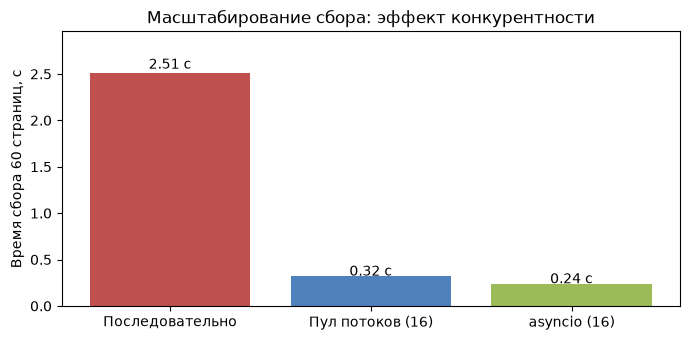

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
labels = ["Последовательно", "Пул потоков (16)", "asyncio (16)"]
times = [t_seq, t_thr, t_async]
bars = ax.bar(labels, times, color=["#c0504d", "#4f81bd", "#9bbb59"])
ax.set_ylim(0, max(times) * 1.18)   # запас, чтобы метки не упирались в рамку
for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width()/2, t*1.02, f"{t:.2f} c", ha="center")
ax.set_ylabel("Время сбора 60 страниц, с")
ax.set_title("Масштабирование сбора: эффект конкурентности")
plt.tight_layout(); plt.show()

**Вывод.** Конкурентность дала ускорение в десятки раз — но это же и главный риск: наш скромный стенд теперь получает 60 запросов за доли секунды. Настоящий сайт вместо каталога покажет страницу с капчей или код 429. Поэтому следующий навык — не разгон, а **управление скоростью**.

## 1.6 Клиентский троттлинг: token bucket

Серверы ограничивают частоту запросов; вежливый сборщик делает это добровольно, на своей стороне. Классический алгоритм — token bucket: корзина с $B$ жетонами, пополняющаяся со скоростью $r$ жетонов/с; запрос возможен только при наличии жетона.

Важная тонкость: корзина с ёмкостью $B$ допускает **начальный всплеск** из $B$ запросов подряд. Поэтому на коротком интервале измеренная скорость может превысить $r$ (в нашем демо ниже — около 12 RPS в первые секунды при номинале 10 RPS), а в долгосрочной перспективе скорость стремится к $r$. Это не ошибка, а свойство алгоритма — так же ведёт себя и серверный rate limiter нашего стенда.

20 запросов за 1.69 с — на коротком интервале выше 10 RPS (всплеск), дальше выравнивается к 10 RPS


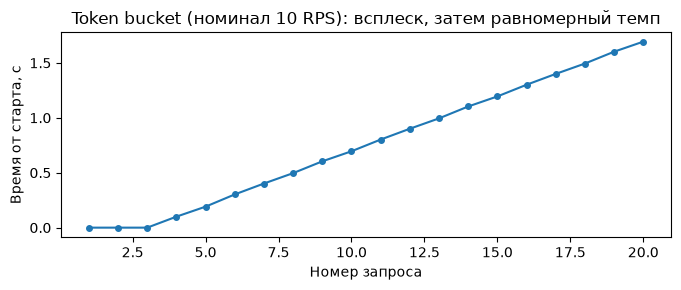

In [9]:
class TokenBucket:
    """Клиентский ограничитель частоты запросов."""
    def __init__(self, capacity, rate):
        self.capacity, self.rate = capacity, rate
        self.tokens = float(capacity)
        self.ts = time.monotonic()

    def acquire(self):
        while True:
            now = time.monotonic()
            self.tokens = min(self.capacity,
                               self.tokens + (now - self.ts) * self.rate)
            self.ts = now
            if self.tokens >= 1.0:
                self.tokens -= 1.0
                return
            time.sleep((1.0 - self.tokens) / self.rate)

bucket = TokenBucket(capacity=3, rate=10)   # номинал 10 запросов/с + всплеск 3
t0 = time.perf_counter()
stamps = []
for i in range(20):
    bucket.acquire()
    stamps.append(time.perf_counter() - t0)
print(f"20 запросов за {stamps[-1]:.2f} с — на коротком интервале выше 10 RPS "
      f"(всплеск), дальше выравнивается к 10 RPS")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, 21), stamps, "o-", ms=4)
ax.set_xlabel("Номер запроса"); ax.set_ylabel("Время от старта, с")
ax.set_title("Token bucket (номинал 10 RPS): всплеск, затем равномерный темп")
plt.tight_layout(); plt.show()

## 1.7 Очередь задач и дедупликация

Промышленный сборщик — это не «цикл по списку URL», а **frontier**: очередь страниц, которые ещё нужно посетить, плюс множество `seen` уже посещённых. Такой же паттерн используют поисковые краулеры. Здесь же живут приоритеты (новости важнее архивов) и правила вежливости (не чаще 1 запроса на хост).

In [10]:
LINK_RE = re.compile(r'href="(/catalog\?page=\d+)"')

def crawl_frontier():
    frontier = deque([f"{site.base}/catalog?page=1"])
    seen, visited = {frontier[0]}, []
    while frontier and len(visited) < 60:
        url = frontier.popleft()
        visited.append(url)
        body = requests.get(url, timeout=5).text
        for link in LINK_RE.findall(body):
            full = site.base + link
            if full not in seen:                    # дедупликация
                seen.add(full)
                frontier.append(full)
    return visited

t0 = time.perf_counter()
visited = crawl_frontier()
print(f"Frontier-обход: {len(visited)} уникальных страниц за {time.perf_counter()-t0:.2f} с")

Frontier-обход: 60 уникальных страниц за 2.42 с


## 1.8 Кэш и conditional GET

Если данные обновляются редко, повторная загрузка — потраченный трафик и лишняя нагрузка. Протокол HTTP решает это из коробки: сервер отдаёт заголовок `ETag` (идентификатор версии содержимого, [RFC 9110, §8.8.3](https://datatracker.ietf.org/doc/rfc9110/)), клиент при повторном запросе присылает `If-None-Match`. Если ничего не изменилось, сервер отвечает **304 Not Modified** — без тела ответа. Так экономится и трафик, и вычисления сервера.

In [11]:
def fetch_with_cache(url, cache={}):
    cached = cache.get(url)
    headers = {"If-None-Match": cached["etag"]} if cached else {}
    r = requests.get(url, headers=headers, timeout=5)
    if r.status_code == 304:
        return "из кэша (304)", len(cached["body"]), cached["body"]
    etag = r.headers.get("ETag")
    if etag:
        cache[url] = {"etag": etag, "body": r.text}
    return "с сервера", len(r.text), r.text

url = site.base + "/robots.txt"
print(f"1-й запрос: {fetch_with_cache(url)[0]}")
print(f"2-й запрос: {fetch_with_cache(url)[0]}")

1-й запрос: с сервера
2-й запрос: из кэша (304)


# 2. Как сайты распознают автоматизированный сбор

Прежде чем «обходить» блокировки, нужно понять, **почему** они срабатывают. Современные анти-бот системы (Cloudflare, Akamai Bot Manager, AWS WAF, DataDome) оценивают десятки сигналов:

| Группа сигналов | Примеры |
|---|---|
| Сетевые | частота и регулярность запросов с одного IP, репутация IP (прокси/VPN/датацентры), география |
| Заголовки | отсутствие/неправильный `User-Agent`, `Accept-Language`, `Referer`; порядок заголовков |
| Отпечатки клиента | выполнение JavaScript, canvas/WebGL-отпечаток, набор шрифтов, `navigator.webdriver = true` |
| TLS | форма ClientHello (JA3/JA4): у `curl` и браузера она разная |
| Поведение | у человека есть «зависания», скролл, случайные движения мыши; бот кликает мгновенно и идеально ровно |
| Структура | бот идёт по страницам 1, 2, 3, … ровно; человек — хаотично |
| Ловушки | honeypot-ссылки (как наш `/trap`), скрытые поля в формах |

Ответы сервера на «подозрительного» клиента, по возрастанию жёсткости:

1. **`429 Too Many Requests`** — «слишком быстро»; код определён в [RFC 6585](https://datatracker.ietf.org/doc/html/rfc6585), часто сопровождается заголовком `Retry-After`;
2. **`403` / `503`** — «подозрительно» (проверка браузера не пройдена);
3. **JS-challenge** — страница с JavaScript-задачей (браузер её решает, `requests` — нет);
4. **Капча** — «докажи, что ты человек»;
5. **Бан IP/аккаунта** — на длительный срок.

Обратите внимание: ни один сигнал не является надёжным по отдельности — решения принимаются по совокупности (риск-скоринг). Именно поэтому «магического рецепта» не существует: чем больше сигналов вы имитируете, тем дороже стоит каждый ваш запрос.

# 3. Корректная обработка блокировок

Задача взрослого сборщика — не «прорваться», а **не попадаться**: собрать данные, не навредив сайту и не нарушая его правила. Разберём четыре базовых паттерна.

## 3.1 Серверный rate limit и наивный клиент

Наш стенд ограничивает `/search` и `/search2`: корзина на 5 запросов, пополнение 2/с. Посмотрим, что видит наивный клиент, который бьёт в поиск без ограничений.

In [12]:
statuses = []
for _ in range(15):
    r = requests.get(site.base + "/search", params={"q": "ноутбук"}, timeout=5)
    statuses.append(r.status_code)
print("Статусы 15 запросов подряд:", statuses)
print(f"Успехов: {statuses.count(200)}, блокировок 429: {statuses.count(429)}")

Статусы 15 запросов подряд: [200, 200, 200, 200, 200, 429, 429, 429, 429, 429, 429, 429, 429, 429, 429]
Успехов: 5, блокировок 429: 10


## 3.2 Экспоненциальный backoff с джиттером

Правильная реакция на `429`/`503`: подождать и повторить, каждый раз удваивая паузу. Обязательный элемент — **джиттер** (случайная добавка): если сто клиентов «ударятся» одновременно и все подождут ровно 2 секунды, волна повторится. Если сервер прислал `Retry-After`, его значение приоритетнее нашей формулы:

$$t_k = \min(t_{\max},\; t_0 \cdot 2^k) + \text{uniform}(0,\; t_0)$$

Сначала посмотрим на сам ряд задержек — экспоненциальный рост плюс случайный джиттер:

In [13]:
def backoff_delay(attempt, retry_after=None):
    """Пауза перед повторной попыткой № attempt (счёт с нуля)."""
    if retry_after is not None:
        return float(retry_after)                    # сервер сказал явно — слушаемся
    return min(8.0, 0.3 * 2**attempt) + random.uniform(0, 0.3)

print("Паузы при 429 без Retry-After (попытка: задержка, с):")
for attempt in range(6):
    print(f"  попытка {attempt}: {backoff_delay(attempt):.2f} с")

print("\nПаузы, если сервер прислал Retry-After: 1, 3, 6 — просто ждём столько")

Паузы при 429 без Retry-After (попытка: задержка, с):
  попытка 0: 0.40 с
  попытка 1: 0.65 с
  попытка 2: 1.40 с
  попытка 3: 2.42 с
  попытка 4: 4.96 с
  попытка 5: 8.11 с

Паузы, если сервер прислал Retry-After: 1, 3, 6 — просто ждём столько


Теперь два живых демо на стенде: сервер, который **присылает** `Retry-After`, и сервер, который его **не присылает** (второй случай — «молчаливый» 429, клиенту приходится самому выбирать паузу).

In [14]:
def get_with_backoff(url, params=None, max_attempts=10):
    """GET с экспоненциальным backoff и уважением Retry-After."""
    history = []
    for attempt in range(max_attempts):
        r = requests.get(url, params=params, timeout=5)
        history.append((attempt, r.status_code))
        if r.status_code == 200:
            return r, history
        if r.status_code not in (429, 503):        # не «пробиваем» 403/404
            return r, history
        ra = r.headers.get("Retry-After")
        time.sleep(backoff_delay(attempt, retry_after=ra))
    return r, history

t0 = time.perf_counter()
r1, hist1 = get_with_backoff(site.base + "/search", {"q": "телефон"})
print(f"/search (есть Retry-After):  {r1.status_code} за {time.perf_counter()-t0:.1f} с, "
      f"хронология: {hist1}")

# осушим корзину /search2, чтобы демонстрация реально попала в блокировку
for _ in range(6):
    requests.get(site.base + "/search2", params={"q": "warm"}, timeout=5)

t0 = time.perf_counter()
r2, hist2 = get_with_backoff(site.base + "/search2", {"q": "планшет"})
print(f"/search2 (без Retry-After):  {r2.status_code} за {time.perf_counter()-t0:.1f} с, "
      f"хронология: {hist2} — паузы выбирал клиент по экспоненте")

/search (есть Retry-After):  200 за 0.1 с, хронология: [(0, 200)]
/search2 (без Retry-After):  200 за 0.4 с, хронология: [(0, 429), (1, 200)] — паузы выбирал клиент по экспоненте


## 3.3 Адаптивный троттлинг (AIMD)

Если лимиты сервера неизвестны, скорость подбирают динамически — как TCP управляет перегрузкой сети (Additive Increase / Multiplicative Decrease):

- успешный ответ → скорость чуть растёт (`+r`);
- блокировка → скорость падает вдвое.

Так сборщик сам находит максимум, который сайт терпит, и автоматически «поджимается», когда сайт занят. Полноценный сборщик обязан также **повторять** неудавшиеся запросы — соберём их в отдельную очередь и дообработаем.

Всего заданий: 20; выполнено с первой попытки: 15; остальные добраны повторами (итог: все 20 выполнены)


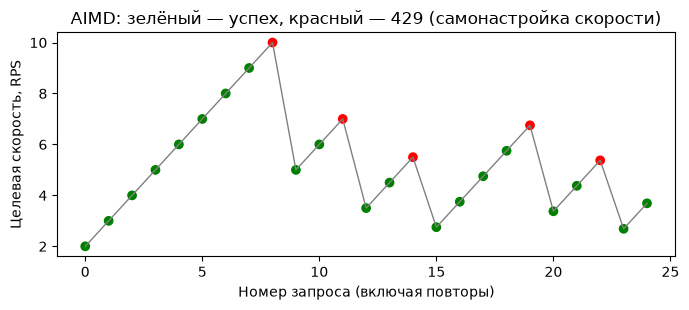

In [15]:
def aimd_crawl(n=20):
    rps, records = 2.0, []
    pending = deque(f"q{i}" for i in range(n))   # все задания
    for round_no in range(4):
        if not pending:
            break
        deferred = deque()
        while pending:
            q = pending.popleft()
            time.sleep(1.0 / rps)
            r = requests.get(site.base + "/search2", params={"q": q}, timeout=5)
            ok = r.status_code == 200
            records.append((len(records), rps, r.status_code))
            if ok:
                rps = min(20.0, rps + 1.0)          # additive increase
            else:
                rps = max(0.5, rps / 2)              # multiplicative decrease
                deferred.append(q)                  # повторим позже
                time.sleep(0.3)
        pending = deferred                          # второй круг
    first_pass = n - sum(1 for r in records if r[2] != 200)
    return records, first_pass, n

records, ok_first, total = aimd_crawl()
print(f"Всего заданий: {total}; выполнено с первой попытки: {ok_first}; "
      f"остальные добраны повторами (итог: все {total} выполнены)")

fig, ax = plt.subplots(figsize=(7, 3.2))
xs = [x[0] for x in records]; ys = [x[1] for x in records]
colors = ["green" if x[2] == 200 else "red" for x in records]
ax.plot(xs, ys, "-", color="gray", lw=1)
ax.scatter(xs, ys, c=colors)
ax.set_xlabel("Номер запроса (включая повторы)"); ax.set_ylabel("Целевая скорость, RPS")
ax.set_title("AIMD: зелёный — успех, красный — 429 (самонастройка скорости)")
plt.tight_layout(); plt.show()

## 3.4 Circuit breaker

Когда сайт лежит или нас жёстко банит, каждый запрос с backoff — лишняя нагрузка. Паттерн circuit breaker (автоматический выключатель) имеет три состояния:

- **CLOSED** — работаем; после $N$ *последовательных* ошибок переходим в OPEN;
- **OPEN** — запросы не отправляем вовсе, «остываем» $T$ секунд;
- **HALF-OPEN** — пропускаем один пробный запрос: успех → CLOSED, провал → OPEN.

Проверим полный цикл: открытие → пауза → пробный запрос → восстановление.

In [16]:
class CircuitBreaker:
    def __init__(self, fail_threshold=3, cooldown=1.0):
        self.fail_threshold, self.cooldown = fail_threshold, cooldown
        self.fails, self.state, self.opened_at = 0, "CLOSED", 0.0

    def allow(self):
        if self.state == "OPEN":
            if time.monotonic() - self.opened_at >= self.cooldown:
                self.state = "HALF-OPEN"        # пробный запрос
                return True
            return False
        return True

    def record(self, ok):
        if self.state == "HALF-OPEN":
            self.state = "CLOSED" if ok else "OPEN"
            if not ok:
                self.opened_at = time.monotonic()
            self.fails = 0
            return
        self.fails = self.fails + 1 if not ok else 0
        if self.fails >= self.fail_threshold:
            self.state, self.opened_at = "OPEN", time.monotonic()

cb = CircuitBreaker(fail_threshold=3, cooldown=1.0)

def try_request(i, ok):
    if cb.allow():
        cb.record(ok)
        print(f"запрос {i:2d}: отправлен, {'успех' if ok else 'ошибка'}, breaker -> {cb.state}")
    else:
        print(f"запрос {i:2d}: пропущен (OPEN — бережём сайт и себя)")

# фаза 1: нормальная работа, затем серия ошибок -> breaker открывается
for i, ok in enumerate([True, True, True, False, False, False]):
    try_request(i, ok)
# фаза 2: breaker OPEN — запросы не отправляем вовсе
for i in range(6, 9):
    try_request(i, True)
# фаза 3: пауза больше cooldown — пробный запрос в HALF-OPEN
time.sleep(1.2)
print("--- пауза больше cooldown: пробуем снова ---")
try_request(9, True)    # HALF-OPEN: успех -> CLOSED
try_request(10, True)   # снова нормальная работа
try_request(11, True)

запрос  0: отправлен, успех, breaker -> CLOSED
запрос  1: отправлен, успех, breaker -> CLOSED
запрос  2: отправлен, успех, breaker -> CLOSED
запрос  3: отправлен, ошибка, breaker -> CLOSED
запрос  4: отправлен, ошибка, breaker -> CLOSED
запрос  5: отправлен, ошибка, breaker -> OPEN
запрос  6: пропущен (OPEN — бережём сайт и себя)
запрос  7: пропущен (OPEN — бережём сайт и себя)
запрос  8: пропущен (OPEN — бережём сайт и себя)
--- пауза больше cooldown: пробуем снова ---
запрос  9: отправлен, успех, breaker -> CLOSED
запрос 10: отправлен, успех, breaker -> CLOSED
запрос 11: отправлен, успех, breaker -> CLOSED


## 3.5 robots.txt: конвенция вежливости

`robots.txt` — стандарт 1994 года ([A Standard for Robot Exclusion](https://www.robotstxt.org/orig.html)), формализованный позже в [RFC 9309](https://developers.google.com/crawling/docs/robots-txt/robots-txt-spec). Это **не закон и не механизм принуждения** — добровольная конвенция: сайт сообщает краулерам, какие разделы обходить не стоит. Крупные поисковые роботы её соблюдают, и вежливый сборщик поступает так же.

Два нюанса, которые часто упускают:

- `Crawl-delay` — это **просьба** сайта держать паузу между запросами. Наши нагрузочные эксперименты выше её сознательно нарушали — но это был наш собственный стенд, и мы сами себе разрешили. На чужом сайте вежливый клиент обязан выдерживать паузу.
- У `urllib.robotparser` есть метод `crawl_delay()` — читаем и соблюдаем.

In [17]:
rp = RobotFileParser()
rp.set_url(site.base + "/robots.txt")
rp.read()
print("Crawl-delay для *:", rp.crawl_delay("*"), "с")
for path in ["/catalog?page=1", "/trap", "/admin", "/search?q=x"]:
    verdict = "РАЗРЕШЕНО" if rp.can_fetch("*", site.base + path) else "ЗАПРЕЩЕНО"
    print(f"  {path:25s} -> {verdict}")

# вежливый клиент: соблюдаем Crawl-delay
t0 = time.perf_counter()
for page in [1, 2, 3]:
    time.sleep(rp.crawl_delay("*") or 0)
    fetch_page(page)
print(f"\n3 страницы с соблюдением Crawl-delay=1: {time.perf_counter()-t0:.1f} с "
      f"(медленно, зато вежливо)")

Crawl-delay для *: 1 с
  /catalog?page=1           -> РАЗРЕШЕНО
  /trap                     -> ЗАПРЕЩЕНО
  /admin                    -> ЗАПРЕЩЕНО
  /search?q=x               -> РАЗРЕШЕНО

3 страницы с соблюдением Crawl-delay=1: 3.1 с (медленно, зато вежливо)


# 4. Капчи и технические методы защиты

## 4.1 Зачем нужны капчи

CAPTCHA (Completely Automated Public Turing test to tell Computers and Humans Apart) — задача, которую человек решает легко, а машина (в идеале) нет. Эволюция поколений:

| Поколение | Пример | Идея | Слабость |
|---|---|---|---|
| 1 | искражённый текст | OCR не читал | современный ML читает искажённый текст надёжнее человека |
| 2 | reCAPTCHA v2 «выберите светофоры» | база знаний + поведенческий анализ | фермы решателей, ML-классификаторы |
| 3 | reCAPTCHA v3, hCaptcha, Cloudflare Turnstile | риск-скоринг: интерактивная головоломка показывается только при высоком риске | — |

Механизм современной капчи (по [документации reCAPTCHA v3](https://developers.google.com/recaptcha/docs/v3) и [Cloudflare Turnstile](https://developers.cloudflare.com/turnstile/)):

1. браузер получает challenge: серию небольших JavaScript-задач (у Turnstile — proof-of-work, пробы веб-API, детект «браузерных причуд»), собирающих сигналы о среде и поведении;
2. по сигналам вычисляется **токен** (у Turnstile — до 2048 символов) и, в случае reCAPTCHA v3, риск-балл от 0.0 («точно бот») до 1.0 («точно человек»);
3. токен отправляется с формой на сервер сайта;
4. сервер сайта проверяет токен у провайдера (Siteverify / siteverify API) — **валидация происходит на сервере провайдера**, не в браузере.

Отсюда важные следствия: токены одноразовые и короткоживущие (Turnstile — 300 секунд, одна валидация; токен reCAPTCHA — 2 минуты), перебор ответов бесполезен, а «картинка» — лишь видимая верхушка риск-системы. Managed-режим Turnstile вообще показывает чекбокс только подозрительным клиентам.

## 4.2 Практикум: простая капча на нашем стенде

Наивный сайт защитил бы форму арифметической капчей — «сколько будет 7 + 5?». Проверим полную цепочку: отказ без токена → challenge → неверный ответ → верный ответ (сервер сам регистрирует токен) → доступ → попытка переиграть использованный challenge. **Напоминаю: мы на своём стенде и решаем свою капчу — это учебная демонстрация слабости такого класса защит.**

In [18]:
# Шаг 0: без токена доступ запрещён
r0 = requests.get(site.base + "/data", timeout=5)
print("0. Без токена:", r0.status_code)

# Шаг 1: получить challenge
challenge = requests.get(site.base + "/login", timeout=5).json()
print("1. Сервер прислал:", challenge)

# Шаг 2: неверный ответ отклоняется, challenge остаётся живым
r_wrong = requests.post(site.base + "/login",
                        json={"session": challenge["session"], "answer": 0},
                        timeout=5)
print("2. Неверный ответ:", r_wrong.status_code)

# Шаг 3: «решить» капчу программно
m = re.search(r"(\d+) \+ (\d+)", challenge["challenge"])
answer = int(m.group(1)) + int(m.group(2))
print(f"3. Бот решает: {m.group(1)} + {m.group(2)} = {answer}")

r_ok = requests.post(site.base + "/login",
                     json={"session": challenge["session"], "answer": answer},
                     timeout=5)
token = r_ok.json()["token"]
print("4. Верный ответ:", r_ok.status_code, "| сервер выдал токен:", token)

# Шаг 4: токен зарегистрирован сервером — доступ открыт
r_data = requests.get(site.base + "/data", params={"token": token}, timeout=5)
print("5. Доступ с токеном:", r_data.status_code, r_data.json())

# Шаг 5: использованный challenge нельзя переиграть
r_replay = requests.post(site.base + "/login",
                         json={"session": challenge["session"], "answer": answer},
                         timeout=5)
print("6. Повтор challenge:", r_replay.status_code, "(одноразовость работает)")

0. Без токена: 401
1. Сервер прислал: {'challenge': 'Сколько будет 5 + 2?', 'session': 's2441955'}
2. Неверный ответ: 403
3. Бот решает: 5 + 2 = 7
4. Верный ответ: 200 | сервер выдал токен: 383545e58b37
5. Доступ с токеном: 200 {'secret': 'данные только для прошедших капчу'}
6. Повтор challenge: 403 (одноразовость работает)


**Разбор.** Арифметическая капча рухнула: задача формулируется на естественном языке, а «решение» — тривиальный парсинг и сложение. При этом серверная часть у нас сделана правильно: токен регистрируется на сервере, challenge одноразовый, доступ без токена закрыт. Уязвим сам **класс задачи** — она слишком легко решается машиной. Именно так умерли текстовые капчи: ML-модели распознавания искажённого текста превзошли людей ещё в 2010-х, и индустрия ушла к риск-скорингу.

Что из этого следует для **защитника**:

- опирайтесь на сигналы, которые дорого подделать (поведение, окружение браузера, репутация IP) — наш арифметический пример показывает, что происходит, когда сигнал дёшев;
- решение должно валидироваться на сервере, быть одноразовым и короткоживущим;
- одна слабая капча хуже отсутствия капчи: она создаёт ложное чувство защищённости.

Что для **сборщика** (этичного): если на пути встала капча — это сигнал «владелец не хочет автоматизации здесь». Правильные пути дальше — раздел 4.4.

## 4.3 Серверы-решатели и ML-обход: почему мы не пишем такой код

Существуют коммерческие сервисы «решения капч» (Anti-Captcha, 2Captcha и др.): они передают картинку человеку за доли цента или прогоняют через ML-модели. Мы сознательно **не интегрируемся** с такими сервисами и не приводим рабочий код ML-распознавания, потому что:

1. это нарушение условий обслуживания практически любого сайта;
2. обход капчи на чужом сайте без разрешения владельца создаёт юридические риски (см. раздел 6);
3. на учебном курсе важно понимать механику, а не строить инструмент злоупотребления.

## 4.4 Легальные альтернативы капчи

Чек-лист, который закрывает большинство реальных задач сбора:

1. **Официальный API** — у большинства сервисов есть; часто платный, но дешевле, чем поддерживать «хрупкий» скрипт-обходчик.
2. **RSS/экспорт/дампы** — новости, каталоги, статистика часто отдаются машинами по запросу.
3. **Открытые данные** — государственные порталы open data, Kaggle, архивы.
4. **Написать владельцу** — для исследовательских задач часто дают доступ; особенно если пообещать не публиковать сырые данные.
5. **Партнёрские программы** — аффилиатные API, реселлерские данные.
6. Если ничего не подходит — спросите себя, **зачем именно эти данные**; ответ часто подсказывает другой источник.

## 4.5 Honeypot: невидимая ловушка

Финальная защита нашего стенда — скрытая ссылка `/trap` (display:none) и запрет в robots.txt. Наивный краулер, который собирает все ссылки со страницы, попадёт в ловушку и получит бан на всём сайте. Вежливый краулер, который читает robots.txt, — нет. Чтобы бан «наивного» не задел «вежливого», клиенты стенда различаются учебным заголовком `X-Forwarded-For` (в реальности банят по IP-адресу).

In [19]:
def get_as(ident, path):
    return requests.get(site.base + path, headers={"X-Forwarded-For": ident}, timeout=5)

NAIVE, POLITE = "10.0.0.1", "10.0.0.2"

body = get_as(NAIVE, "/catalog?page=1").text
links = re.findall(r'href="(/[^"]+)"', body)
print("Ссылки на странице каталога (для всех одинаковы):", links)

# наивный краулер идёт по ВСЕМ ссылкам, включая невидимую ловушку
r_trap = get_as(NAIVE, links[0])
print(f"\nНаивный краулер запросил {links[0]} -> {r_trap.status_code} (попал в honeypot)")

r_after = get_as(NAIVE, "/catalog?page=2")
print(f"Следующий запрос наивного краулера -> {r_after.status_code} "
      "(забанен на всём сайте)")

# вежливый краулер сначала читает robots.txt и ловушку не трогает
rp_local = RobotFileParser(); rp_local.set_url(site.base + "/robots.txt"); rp_local.read()
safe_links = [l for l in links if rp_local.can_fetch("*", site.base + l)]
print(f"\nВежливый краулер видит только: {safe_links}")
r_polite = get_as(POLITE, safe_links[0])
print(f"Вежливый краулер продолжает работу -> {r_polite.status_code} (не забанен)")

Ссылки на странице каталога (для всех одинаковы): ['/trap', '/catalog?page=2']

Наивный краулер запросил /trap -> 403 (попал в honeypot)
Следующий запрос наивного краулера -> 403 (забанен на всём сайте)

Вежливый краулер видит только: ['/catalog?page=2']
Вежливый краулер продолжает работу -> 200 (не забанен)


# 5. No-code платформы сбора

Когда код писать не хочется или не нужно, задачу закрывают визуальные платформы. Важно понимать: **под капотом у них те же HTTP-запросы и браузеры**, просто ими управляет не ваш код, а граф конфигурации.

| Платформа | Модель | Сильные стороны | Ограничения |
|---|---|---|---|
| Apify | облачные «акторы» + магазин готовых сборщиков | экосистема, планировщик, прокси-инфраструктура | оплата за потребление |
| Octoparse | десктопный конструктор + облако | визуальный клик по элементам, шаблоны | тяжёлый JS без прокси-тарифов |
| ParseHub | десктопный конструктор | быстрый старт для таблиц | ограниченная масштабируемость |
| Browse AI / Browserflow | браузерные расширения | «записал — воспроизвёл», мониторинг | мелкие объёмы |

Три вещи, которые no-code **не снимает** с вас:

1. **Юридическую ответственность** — платформа выполняет действия от вашего имени; нарушение правил сайта остаётся вашим нарушением.
2. **Этику** — визуальный инструмент так же легко направить на чужие данные, как и код; решения должен принимать человек.
3. **Хрупкость** — если сайт меняет вёрстку или защиту, конфигурация ломается так же, как селекторы в коде.

## 5.1 Как устроен no-code изнутри: мини-движок

Чтобы «no-code» не был магией, напишем крошечный движок, который исполняет **декларативную конфигурацию** — ровно то, что делают визуальные платформы: вы описываете стартовый URL, пагинацию, шаблон данных, лимит скорости и правила вежливости, а движок обходит сайт и складывает результат в таблицу. Конфигурация — данные; движок — код; вместе — «no-code».

In [20]:
NOCODE_CONFIG = {
    "name": "catalog-collector",
    "start_url_template": site.base + "/catalog?page={page}",
    "pagination": {"param": "page", "from": 1, "to": 60},
    "extract": {"item_pattern": r"<li>(.*?)</li>"},
    "rate_limit_rps": 20,
    "respect_robots": True,
    "export": "lesson07_items.csv",
}

def run_nocode_engine(cfg):
    rp_cfg = RobotFileParser()
    rp_cfg.set_url(site.base + "/robots.txt"); rp_cfg.read()
    rows, pages, skipped = [], 0, 0
    for page in range(cfg["pagination"]["from"], cfg["pagination"]["to"] + 1):
        url = cfg["start_url_template"].format(page=page)
        if cfg["respect_robots"] and not rp_cfg.can_fetch("*", url):
            skipped += 1
            continue
        time.sleep(1.0 / cfg["rate_limit_rps"])          # клиентский троттлинг
        body = requests.get(url, timeout=5).text
        for item in re.findall(cfg["extract"]["item_pattern"], body):
            rows.append({"page": page, "item": item})
        pages += 1
    return rows, pages, skipped

t0 = time.perf_counter()
rows, pages, skipped = run_nocode_engine(NOCODE_CONFIG)
with open(NOCODE_CONFIG["export"], "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["page", "item"])
    writer.writeheader(); writer.writerows(rows)

print(f"Движок по конфигурации: страниц {pages}, пропущено по robots.txt {skipped}, "
      f"товаров {len(rows)}, время {time.perf_counter()-t0:.1f} с")
print(f"Экспорт: {NOCODE_CONFIG['export']} — первые строки:")
for r in rows[:3]:
    print("  ", r)

Движок по конфигурации: страниц 60, пропущено по robots.txt 0, товаров 600, время 5.7 с
Экспорт: lesson07_items.csv — первые строки:
   {'page': 1, 'item': 'Товар 01-001'}
   {'page': 1, 'item': 'Товар 01-002'}
   {'page': 1, 'item': 'Товар 01-003'}


Проверка полноты: 60 страниц × 10 товаров = 600 записей — движок собрал всё. Именно такие проверки («ожидалось N, получено N») обязательны для любого no-code сбора: визуальная платформа легко «промолчит» о потерянных страницах.

## 5.2 Что предлагают реальные платформы

Возьмём Apify Web Scraper — его [схема входных параметров](https://apify.com/apify/web-scraper/input-schema) публична и показательна. Обратите внимание на рычаги вежливости и их значения по умолчанию:

| Параметр | Смысл | По умолчанию |
|---|---|---|
| `respectRobotsTxtFile` | консультироваться с robots.txt перед обходом | **false** — включать сами! |
| `maxConcurrency` | потолок одновременных страниц | 50 (у разных акторов 10–200) |
| `rateLimitDelaySecs` | пауза перед каждым запросом | 0.1 с |
| `maxRequestRetries` | повторы при ошибках загрузки | 3 |

Урок из таблицы: **no-code платформа по умолчанию может вести себя невежливо** — «уважение к robots.txt» и щадящий темп нужно включать осознанно. Ответственность за это остаётся на пользователе.

Важное ограничение нашей песочницы: облачная no-code платформа физически не сможет обратиться к `localhost` нашего стенда (она работает в облаке, а стенд — на вашей машине). Поэтому выше мы исполнили конфигурацию собственным мини-движком — он делает ровно то же, что платформа, но локально.

# 6. Правовые и этические границы

Технически возможно почти всё. Юридически и этически — нет. Карта ограничений:

## Что регулирует что

| Инструмент | Юридический статус |
|---|---|
| `robots.txt` | добровольная конвенция 1994 года ([robotstxt.org](https://www.robotstxt.org/orig.html)), формализована в RFC 9309; никем не принуждается, но её соблюдение — признак добросовестности |
| Условия использования (ToS) сайта | правила пользования сервисом; сбор вопреки им может образовать нарушение договора — это и «приземлило» hiQ (ниже) |
| Законы о несанкционированном доступе | обход капч/логина на чужом сайте может квалифицироваться как обход технических средств защиты — зависит от юрисдикции и обстоятельств |
| Персональные данные (GDPR, 152-ФЗ) | сбор данных о людях: нужны основания и правила хранения |
| Авторское право | факты и данные обычно не охраняются, но компиляции и тексты — да |

## Кейс для семинара: hiQ v. LinkedIn

Показательная американская история (см. [разбор итога дела](https://www.morganlewis.com/blogs/sourcingatmorganlewis/2022/12/linkedin-v-hiq-landmark-data-scraping-suit-provides-guidance-to-data-scrapers-and-web-operators)):

- 2017: LinkedIn требует от аналитической компании hiQ прекратить сбор публичных профилей; hiQ подаёт в суд и сначала выигрывает — апелляционный суд дважды признал, что сбор публично доступных страниц, скорее всего, **не нарушает** закон о компьютерных преступлениях (CFAA);
- но в 2022 суд удовлетворяет требование LinkedIn о **нарушении пользовательского соглашения** (hiQ собирал данные и через поддельные аккаунты);
- декабрь 2022: мировое соглашение — hiQ выплачивает $500 000, навсегда запрещает себе сбор LinkedIn и уничтожает собранные данные и код. Компания к этому моменту уже не работала.

Мораль для инженера: даже «выигрышная» техническая позиция не спасает от договорной ответственности, а цена спора несопоставима с ценой легального сбора.

## Чек-лист легального сбора (повесьте над монитором)

1. Есть ли официальный API или открытые данные? Если да — используйте их.
2. Прочитан ли robots.txt и ToS сайта? Соблюдаете ли вы их (включая `Crawl-delay`)?
3. Ограничили ли вы частоту запросов (не мешаете ли работе сайта)?
4. Не собираете ли персональные данные без основания?
5. Кэшируете ли результаты, чтобы не качать одно и то же?
6. Указываете ли честный `User-Agent` с контактом?
7. Готовы ли вы объяснить цель сбора владельцу сайта?

Если хотя бы на два вопроса ответ «нет/не знаю» — остановитесь и переосмыслите задачу.

# Итоги

1. **Масштабирование** — это конкурентность (потоки/asyncio) плюс самоограничение (semaphore, token bucket) плюс очередь задач с дедупликацией и кэш (conditional GET).
2. **Блокировки** почти всегда заслуженны: сайты защищаются от нагрузки и злоупотреблений. Правильная реакция — `Retry-After`, backoff с джиттером (в обоих режимах: с заголовком и без), AIMD с повторами, circuit breaker, robots.txt с `Crawl-delay`.
3. **Капчи** — это серверно-валидированные риск-системы, а не картинки-загадки. Простые капчи (как наша арифметическая) уязвимы как класс; современные держатся на поведенческих сигналах и одноразовых короткоживущих токенах. Их обход на чужих сайтах — нарушение ToS и источник юридических рисков; легальный путь — API, открытые данные, договорённость с владельцем.
4. **No-code** — это декларативная конфигурация плюс движок; платформы не снимают ни юридической, ни этической ответственности, а «уважение к robots.txt» часто нужно включать вручную.
5. Главный навык инженера сбора — не «прорываться», а **договариваться**: с сайтом (вежливость), с владельцем (API) и с законом.

## Вопросы для самопроверки

1. Почему `requests` в цикле медленнее пула потоков даже на одном ядре?
2. Что произойдёт, если сто клиентов одновременно применят backoff без джиттера?
3. Чем `429` отличается от `403` по смыслу и по правильной реакции клиента? Почему `Retry-After` приоритетнее собственной формулы задержки?
4. Зачем нужен `If-None-Match`, если можно просто сохранить ответ локально?
5. Почему honeypot-ловушка работает против наивных краулеров и как её избегает вежливый?
6. Почему арифметическая капча не защищает сайт, даже если токен валидируется на сервере? Какие сигналы использует современная капча вместо неё?
7. Что делает токен капчи «одноразовым» и почему его нельзя просто перебрать?
8. В чём разница между robots.txt и законом? Какой пункт ToS «приземлил» hiQ?
9. Какие три ответственности no-code платформа не снимает с вас?
10. Перечислите пять легальных альтернатив обходу капчи.

## Домашнее задание (мини-проект)

Расширьте учебный стенд и сборщика:

1. **Стенд**: добавьте к `MiniSite` endpoint `/catalog/slow` с `Crawl-delay: 2` в robots.txt и серверной проверкой, что клиент не приходит чаще.
2. **Сборщик**: соберите все 60 страниц каталога со скоростью не выше 5 RPS, с backoff при 429, дедупликацией, кэшированием ETag и очередью повторов для запросов, получивших 429.
3. **Отчёт** (1 страница): какие защиты сработали, какие паттерны обработки применили, что бы вы сделали на реальном сайте.

Критерии: **полнота данных** (60/60 страниц, 600/600 товаров), **корректная обработка повторов** (429 в процессе допустимы, если все задания в итоге выполнены и лог повторов чист), объяснение каждого паттерна в терминах вежливого сбора.

## Источники

1. RFC 9110 «HTTP Semantics» (Retry-After, ETag): https://datatracker.ietf.org/doc/rfc9110/
2. RFC 6585 «Additional HTTP Status Codes» (429): https://datatracker.ietf.org/doc/html/rfc6585
3. A Standard for Robot Exclusion (1994): https://www.robotstxt.org/orig.html
4. Google: интерпретация robots.txt (RFC 9309): https://developers.google.com/crawling/docs/robots-txt/robots-txt-spec
5. Документация reCAPTCHA v3 (риск-балл 0.0–1.0): https://developers.google.com/recaptcha/docs/v3
6. Документация Cloudflare Turnstile (proof-of-work, одноразовые токены): https://developers.cloudflare.com/turnstile/
7. Apify Web Scraper — схема входных параметров: https://apify.com/apify/web-scraper/input-schema
8. Morgan Lewis: разбор итога дела LinkedIn v. hiQ (2022): https://www.morganlewis.com/blogs/sourcingatmorganlewis/2022/12/linkedin-v-hiq-landmark-data-scraping-suit-provides-guidance-to-data-scrapers-and-web-operators

In [19]:
site.stop()
print("Стенд остановлен. Занятие 7 завершено.")

Стенд остановлен. Занятие 7 завершено.
